First we import the library, and we instantiate an STLDriver object. 

In [1]:
import stlrom
monitor = stlrom.STLDriver()

Then, we declare signals, parameters (optional), and formulas. 

In [2]:
monitor.parse_string("signal x, y")       # declaring signals named 'x' and 'y'
monitor.parse_string("param p=0.2, tau=1") # declaring parameters named 'p' and 'tau'
monitor.parse_string("interval i1=[-1,3], i2=[0.2,tau]") # declaring intervals named 'i1' and 'i2'

monitor.parse_string("mu_x := x[t] > p ") # an atomic proposition
monitor.parse_string("mu_y := y[t] < [-2,1] ") # another atomic proposition
monitor.parse_string("mu_in := x[t] in i1 ") # a proposition using "in" operator
monitor.parse_string("mu := mu_x and mu_y") # a compound proposition
monitor.parse_string("phi := ev_[0, tau] mu") # a temporal proposition
monitor.parse_string("phi2 := alw_[i2] mu_in") # a temporal proposition using intervals (for time domain and for the proposition)
monitor.disp()

# STLDriver object defined as
signal x, y
param p=0.2, tau=1
interval i1=[-1,3], i2=[0.2,tau]

# With formulas:
mu := x[t] > p and y[t] < [-2,1]
mu_in := x[t] in i1
mu_x := x[t] > p
mu_y := y[t] < [-2,1]
phi := ev_[0,tau] (x[t] > p and y[t] < [-2,1]) 
phi2 := alw_[0.2,tau] (x[t] in i1) 

# Data:
# No data yet.


We can now add data and bounds. We do it by adding time valued samples of the form [t, x, y], and [t, [x_lb, x_ub], [y_lb, y_ub]] for bounds.

In [3]:
monitor.add_sample([0, 2., 3.])     # at time 0, x=2, y=3
monitor.add_sample([0.5, -1., -4.]) # at time 0.5, x=-1, y=-4
monitor.add_sample([3, 3., -5.])    # etc.
monitor.add_bounds([0, [1.5,2.4], [0.5,3.8]]) # at time 0, x\in[0,4], y\in[1,4]
monitor.add_bounds([0.8, [-3,0], [-8,-1]])
monitor.add_lower_bound([1.5, 0., -7]) # at time 1.5, x_low=0, y_low=-7
monitor.add_bounds([3, [2.5,3.5], [-9,-4]])
print(monitor.data)

# Signal x:
3 samples from t0=0 to t_end=3
# Signal y:
3 samples from t0=0 to t_end=3



We can now plot the signals with bounds.

<Axes: xlabel='Time', ylabel='Value'>

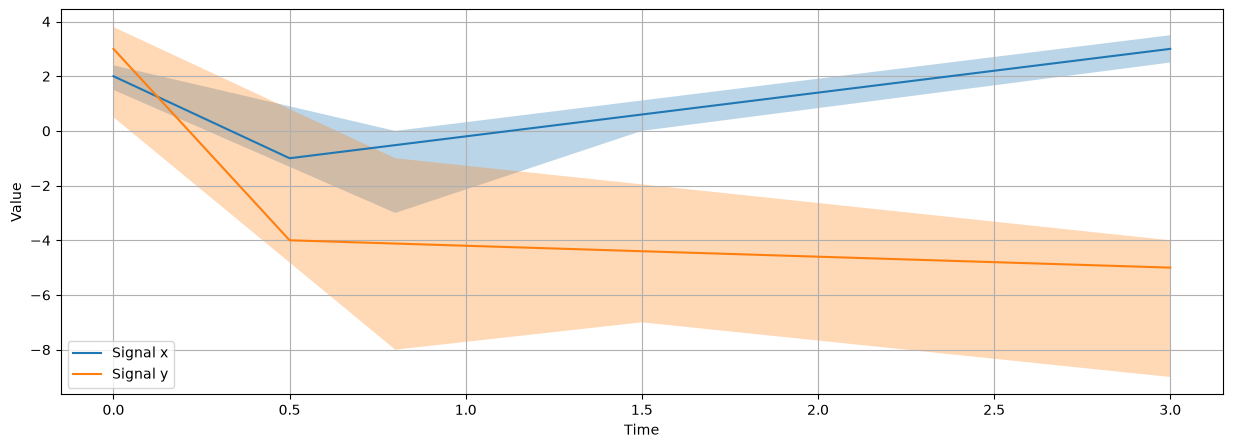

In [4]:
monitor.plot_signals(draw_tube=True)

We can also set bounds with the inflate function, that set the bounds to a radius of r from the signal.

<Axes: xlabel='Time', ylabel='Value'>

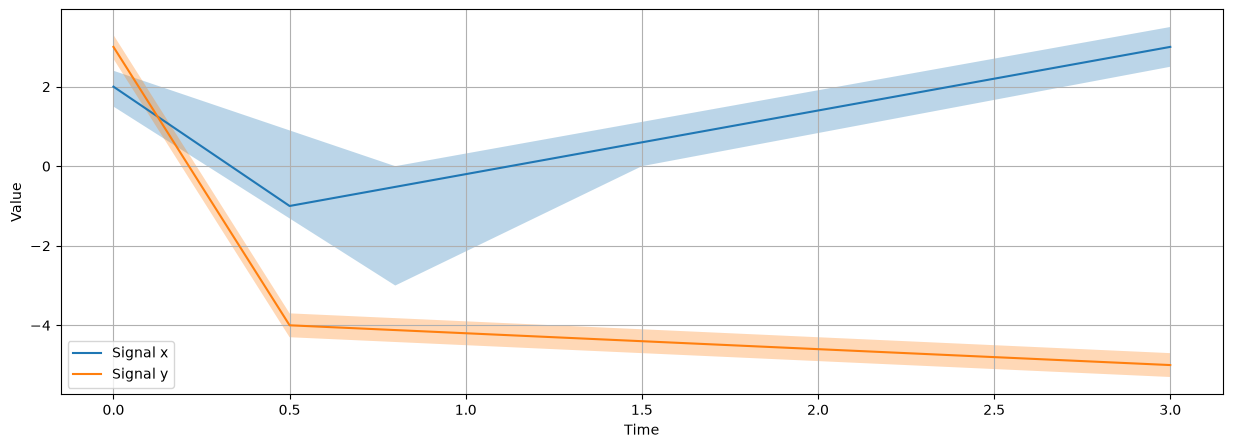

In [5]:
monitor.data.inflate_signal("y", 0.3)
monitor.plot_signals(draw_tube=True)

We are now ready to evaluate formulas. For this we use the get_online_rob() method to get [rob, lower_rob, upper_rob] at t=0. 

In [6]:
rob_mu_y  = monitor.get_online_rob("mu_y")
rob_mu_in = monitor.get_online_rob("mu_in")
rob_phi   = monitor.get_online_rob("phi")

print("rob_mu_y = ", rob_mu_y)
print("rob_mu_in = ", rob_mu_in)
print("rob_phi = ", rob_phi)

rob_mu_y =  [-3.5, -5.300000000000001, -1.6999999999999997]
rob_mu_in =  [1.0, 0.6000000000000001, 1.5]
rob_phi =  [0.2100000000000004, -5.300000000000001, -1.6999999999999997]


We can also get the robustness signal with bounds and plot them.

Text(0.5, 1.0, 'phi := ev_[0,1] (x[t] > 0.2 and y[t] < [-2,1])')

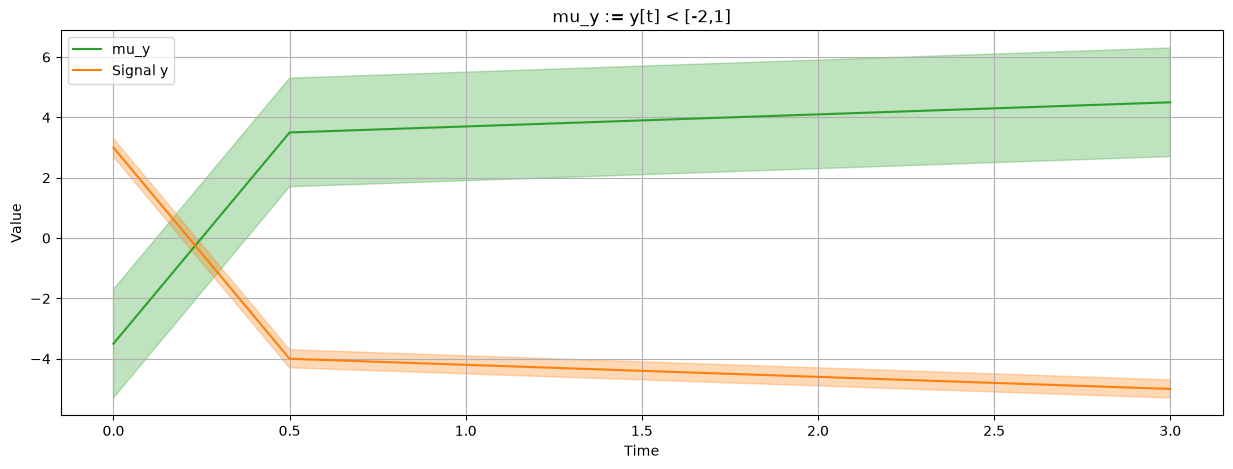

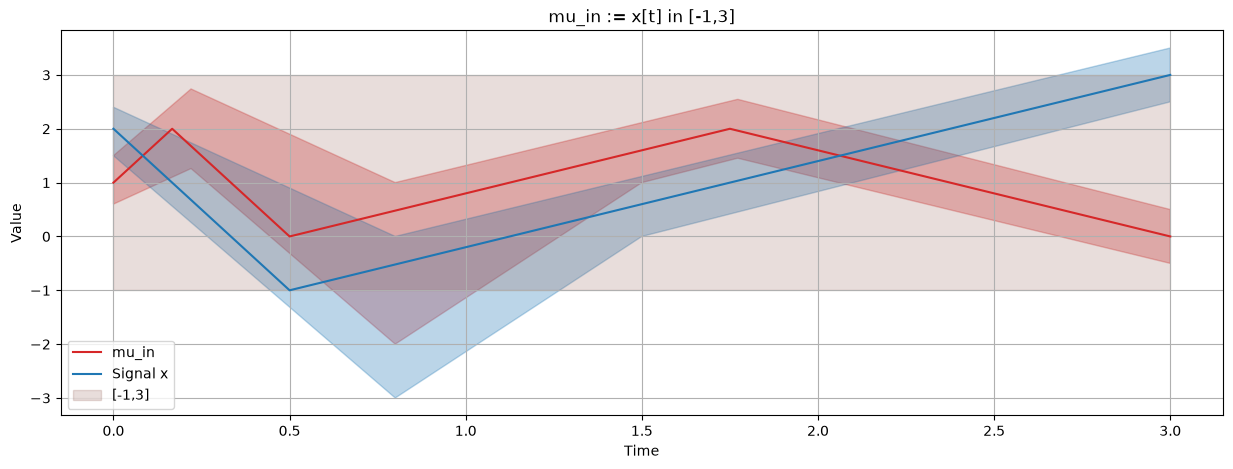

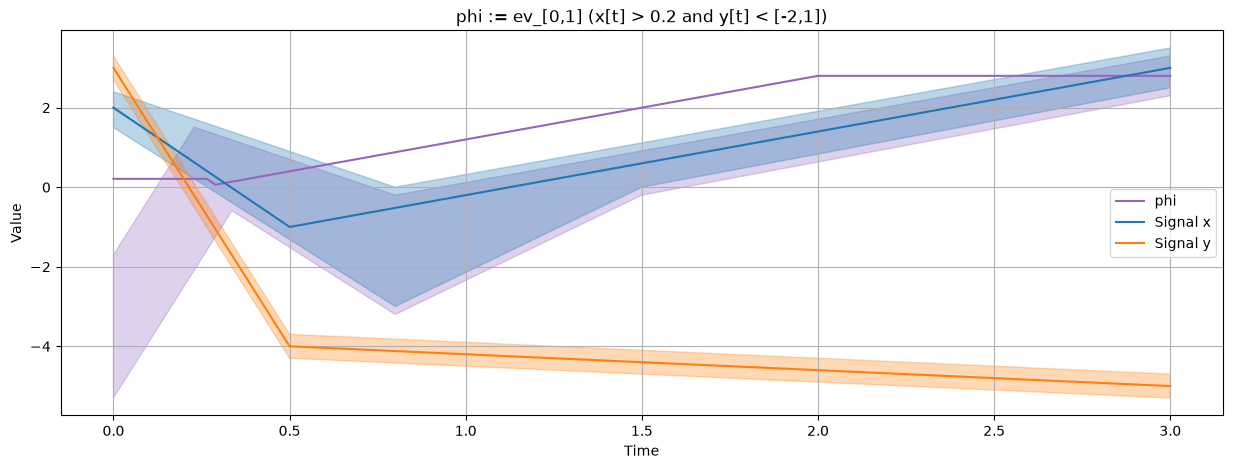

In [7]:
# sig_rob_mu_y  = monitor.get_online_rob_signal("mu_y",0.,3.)
ax = monitor.plot_online_rob("mu_y", 0., 3., color="C2")
monitor.plot_signal("y", ax=ax, draw_tube=True, color="C1")
ax.set_title("mu_y := y[t] < [-2,1]")

# sig_rob_mu_in = monitor.get_online_rob_signal("mu_in")
ax = monitor.plot_online_rob("mu_in", 0., 3., color="C3")
monitor.plot_signal("x", ax=ax, draw_tube=True, color="C0")
ax.fill([0,3.,3.,0.], [-1,-1,3,3], edgecolor="C5", facecolor="C5", alpha=0.2, label="[-1,3]")
ax.legend()
ax.set_title("mu_in := x[t] in [-1,3]")

# sig_rob_phi   = monitor.get_online_rob_signal("phi")
ax = monitor.plot_online_rob("phi", 0., 3., color="C4")
monitor.plot_signal("x", ax=ax, draw_tube=True, color="C0")
monitor.plot_signal("y", ax=ax, draw_tube=True, color="C1")
ax.set_title("phi := ev_[0,1] (x[t] > 0.2 and y[t] < [-2,1])")